<a href="https://colab.research.google.com/github/fattah-abdullah/ProyekAkhir_5A_CardiovascularDisease/blob/main/P13_Perbandingan_dan_Pemilihan_Kelompok6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pertemuan 13 — Membandingkan Tiga Varian dan Memilih Satu
## Proyek Akhir Pembelajaran Mesin (INF62325) — Cabang A: Regresi Linear

| | |
|---|---|
| Kelompok | 6 |

| Anggota | NIM | Varian |
|---|---|---|
| Abdullah Fattah | 2488010067 | 1 — Dasar |
| Mifa Miftahul Falaah | 2488010072 | 2 — Perlakuan data |
| Salwa Ayudia Putri | 2488010042 | 3 — Pemilihan fitur |

---

### Panduan Pertemuan 13

**Notebook ini dikerjakan bersama.** Ketiga anggota duduk bersama, karena
keputusan yang diambil di sini milik kelompok.

**Masukan.** `p12_data.joblib` ditambah enam berkas hasil ketiga notebook
varian. Bila salah satu anggota belum selesai, notebook ini berhenti dan
menyebutkan varian mana yang kurang.

**Yang dikerjakan.** Menabulasi hasil ketiga varian, memeriksa bahwa ketiganya
memang diukur pada data uji yang sama, memilih satu, lalu menafsirkan varian
terpilih lewat koefisien dan grafik residualnya.

**Luaran.** `model_terpilih.joblib` dan `p13_metrik.json`.

**Yang dinilai bukan varian mana yang menang.** Yang dinilai adalah apakah
setiap anggota bisa menjelaskan mengapa variannya menang atau kalah.

**Perkiraan waktu.** 90 menit.

---
## Langkah A — Samakan versi scikit-learn (WAJIB, setiap kali membuka notebook ini)

Colab memulai sesi baru setiap kali notebook dibuka, jadi langkah ini diulang
**di setiap pertemuan**, bukan sekali saja.

Gunanya menyamakan versi scikit-learn di Colab dengan versi yang dipasang
Streamlit Community Cloud. Tanpa ini, model berhasil dilatih tetapi gagal dimuat
di aplikasi web dengan galat
`AttributeError: ... has no attribute '_RemainderColsList'`.

In [15]:
!pip install -q scikit-learn==1.9.1

### Restart dulu, jangan dilewati

Pilih menu **Runtime → Restart session**, lalu jalankan ulang dari sel paling atas.
Tanpa restart, Python masih memakai scikit-learn versi lama yang sudah terlanjur
dimuat ke memori, dan kesalahannya tidak terlihat sampai tahap paling akhir.

In [16]:
import sklearn

print("scikit-learn:", sklearn.__version__)
assert sklearn.__version__ == "1.9.1", (
    "Versi belum sesuai. Jalankan sel pip di atas, lalu Runtime -> Restart session, "
    "lalu jalankan ulang dari sel paling atas."
)
print("Versi sudah sesuai.")

scikit-learn: 1.9.1
Versi sudah sesuai.


---
## Langkah B — Hubungkan Google Drive

Setiap pertemuan menyimpan hasilnya ke satu folder Drive yang sama, lalu pertemuan
berikutnya membacanya dari sana. Dengan begitu pekerjaan tidak hilang saat sesi Colab
berakhir, dan tidak perlu mengulang dari awal tiap minggu.

Folder yang dipakai: `/content/drive/MyDrive/ProyekAkhirML_RegresiLinear`

Saat sel di bawah dijalankan, Colab meminta izin mengakses Drive. Pilih akun Google
kelompok, lalu setujui.

In [17]:
import os
from google.colab import drive

drive.mount("/content/drive")

FOLDER = "/content/drive/MyDrive/ProyekAkhirML_RegresiLinear"
os.makedirs(FOLDER, exist_ok=True)

print("Folder proyek:", FOLDER)
print("Isi folder   :", sorted(os.listdir(FOLDER)) or "(masih kosong)")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folder proyek: /content/drive/MyDrive/ProyekAkhirML_RegresiLinear
Isi folder   : ['data_mentah.csv', 'model_terpilih.joblib', 'p12_data.joblib', 'p13_metrik.json', 'varian1.joblib', 'varian1_hasil.json', 'varian2.joblib', 'varian2_hasil.json', 'varian3.joblib', 'varian3_hasil.json']


---
## Langkah C — Muat hasil ketiga varian

In [18]:
PEMILIK = {
    1: ("Varian 1 - Dasar", "P12A_Varian1_Dasar.ipynb"),
    2: ("Varian 2 - Perlakuan Data", "P12B_Varian2_Perlakuan_Data.ipynb"),
    3: ("Varian 3 - Pemilihan Fitur", "P12C_Varian3_Pemilihan_Fitur.ipynb"),
}

kurang = []
if not os.path.exists(os.path.join(FOLDER, "p12_data.joblib")):
    kurang.append("  p12_data.joblib  -> jalankan P12_Data_Bersama.ipynb")

for n, (nama, notebook) in PEMILIK.items():
    for berkas in (f"varian{n}.joblib", f"varian{n}_hasil.json"):
        if not os.path.exists(os.path.join(FOLDER, berkas)):
            kurang.append(f"  {berkas}  -> {nama}, jalankan {notebook}")

if kurang:
    print("Berkas berikut belum ada di folder Drive:\n" + "\n".join(kurang))
    print("\nIsi folder sekarang:", sorted(os.listdir(FOLDER)))
    raise SystemExit(
        "Pertemuan 13 belum bisa dijalankan. Anggota yang variannya disebut "
        "di atas menyelesaikan notebooknya lebih dulu."
    )

print("Lengkap. Ketiga varian sudah dikerjakan.")

Lengkap. Ketiga varian sudah dikerjakan.


In [19]:
import joblib
import json
import numpy as np
import pandas as pd

p12 = joblib.load(os.path.join(FOLDER, "p12_data.joblib"))
X_latih = p12["X_latih"]; X_uji = p12["X_uji"]
y_latih = p12["y_latih"]; y_uji = p12["y_uji"]
TARGET = p12["TARGET"]

model = {}
hasil = {}
for n in (1, 2, 3):
    model[n] = joblib.load(os.path.join(FOLDER, f"varian{n}.joblib"))
    with open(os.path.join(FOLDER, f"varian{n}_hasil.json"), encoding="utf-8") as f:
        hasil[n] = json.load(f)
    h = hasil[n]
    print(f"Varian {n} - {h['anggota']}")
    print(f"   fitur : {h['fitur_numerik']} + {h['fitur_kategorik'] or '(tanpa kategorik)'}")
    print(f"   latih : {h['baris_latih']} baris")
    print(f"   catatan: {h['catatan']}\n")

Varian 1 - (Salwa Ayudia Putri, 2488010042)
   fitur : ['ap_lo', 'height', 'weight', 'age'] + (tanpa kategorik)
   latih : 55993 baris
   catatan: Seluruh fitur numerik apa adanya, imputasi median, tanpa penskalaan dan tanpa kolom kategorik.

Varian 2 - (Mifa Miftahul Falaah, 2488010072)
   fitur : ['ap_lo', 'height', 'weight', 'age'] + (tanpa kategorik)
   latih : 50616 baris
   catatan: Pencilan IQR dibuang dari data latih (5377 baris, 9.6%), lalu fitur numerik diskalakan.

Varian 3 - (Abdullah Fattah, 2488010067)
   fitur : ['weight', 'age', 'ap_lo'] + ['gender', 'cholesterol', 'gluc', 'smoke', 'alco', 'active']
   latih : 55993 baris
   catatan: Fitur numerik disaring pada ambang korelasi 0.01, kolom kategorik ditambahkan lewat one-hot.



### Pemeriksaan sidik jari — WAJIB LOLOS

Sel ini membuktikan ketiga varian diukur pada data uji yang sama. Bila gagal,
tabel perbandingan di bawahnya tidak bermakna, karena selisih angkanya bisa
berasal dari pembagian data yang berbeda.

In [20]:
sidik_p12 = p12["sidik_jari_uji"]
print("Sidik jari data uji di P12:", sidik_p12)

beda = [n for n in (1, 2, 3) if hasil[n]["sidik_jari_uji"] != sidik_p12]
for n in (1, 2, 3):
    tanda = "BEDA" if n in beda else "cocok"
    print(f"  Varian {n}: {hasil[n]['sidik_jari_uji']}  {tanda}")

assert not beda, (
    f"Varian {beda} memakai data uji yang berbeda.\n"
    "Anggota yang bersangkutan menjalankan ulang notebook variannya tanpa\n"
    "mengubah pembagian data, lalu Pertemuan 13 diulang dari awal."
)
print("\nKetiga varian diuji pada data uji yang sama. Perbandingan sah.")

Sidik jari data uji di P12: 3e147073c4769645
  Varian 1: 3e147073c4769645  cocok
  Varian 2: 3e147073c4769645  cocok
  Varian 3: 3e147073c4769645  cocok

Ketiga varian diuji pada data uji yang sama. Perbandingan sah.


---
## Langkah D — Garis dasar

Model yang selalu menjawab rata-rata. Ketiga varian harus mengalahkannya; bila
tidak, fitur yang dipakai tidak mengandung informasi tentang target.

In [21]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

garis_dasar = DummyRegressor(strategy="mean").fit(X_latih, y_latih)
duga_dasar = garis_dasar.predict(X_uji)

mae_dasar = mean_absolute_error(y_uji, duga_dasar)
rmse_dasar = float(np.sqrt(mean_squared_error(y_uji, duga_dasar)))
r2_dasar = r2_score(y_uji, duga_dasar)

print(f"Garis dasar: MAE={mae_dasar:,.2f}  RMSE={rmse_dasar:,.2f}  R2={r2_dasar:.4f}")

Garis dasar: MAE=14.27  RMSE=25.87  R2=-0.0056


---
## Langkah E — Tabel perbandingan

Inilah luaran utama Pertemuan 13. Angkanya datang dari berkas hasil ketiga
anggota, bukan dihitung ulang di sini.

In [22]:
baris = [{"varian": "Garis dasar (rata-rata)", "MAE": mae_dasar,
          "RMSE": rmse_dasar, "R2": r2_dasar}]
for n in (1, 2, 3):
    h = hasil[n]
    baris.append({"varian": h["nama"], "MAE": h["mae"],
                  "RMSE": h["rmse"], "R2": h["r2"]})

tabel_varian = pd.DataFrame(baris).round(4)
tabel_varian

,varian,MAE,RMSE,R2
0,Garis dasar (rata-rata),14.2690,25.8689,-0.0056
1,Dasar,13.1036,25.1210,0.0517
2,Perlakuan Data,30.1458,242.1922,-87.1445
3,Pemilihan Fitur,12.8648,25.0432,0.0576


In [23]:
# Menghafal data latih atau tidak
print("Selisih R2 data latih dan data uji:")
for n in (1, 2, 3):
    h = hasil[n]
    print(f"  Varian {n}: latih={h['r2_latih']:.4f}  uji={h['r2']:.4f}  "
          f"selisih={h['r2_latih'] - h['r2']:+.4f}")

print("\nKestabilan menurut validasi silang:")
for n in (1, 2, 3):
    h = hasil[n]
    print(f"  Varian {n}: rata-rata R2={h['cv_rata']:.4f}  "
          f"simpangan baku={h['cv_simpangan']:.4f}")

terbaik = max((1, 2, 3), key=lambda n: hasil[n]["r2"])
kedua = sorted((1, 2, 3), key=lambda n: hasil[n]["r2"])[-2]
jarak = hasil[terbaik]["r2"] - hasil[kedua]["r2"]
simpangan_terbesar = max(hasil[n]["cv_simpangan"] for n in (terbaik, kedua))

print(f"\nSelisih R2 antara dua varian teratas: {jarak:.4f}")
print(f"Simpangan baku validasi silang terbesar di antara keduanya: {simpangan_terbesar:.4f}")
if jarak < simpangan_terbesar:
    print("\nSelisihnya LEBIH KECIL daripada keragaman antar-lipatan.")
    print("Belum cukup untuk menyatakan satu varian lebih baik. Tuliskan ini")
    print("apa adanya di sel isian; memilih salah satunya tetap boleh, asalkan")
    print("alasannya bukan 'angkanya lebih tinggi'.")

Selisih R2 data latih dan data uji:
  Varian 1: latih=0.0012  uji=0.0517  selisih=-0.0505
  Varian 2: latih=0.0041  uji=-87.1445  selisih=+87.1486
  Varian 3: latih=0.0015  uji=0.0576  selisih=-0.0560

Kestabilan menurut validasi silang:
  Varian 1: rata-rata R2=0.0013  simpangan baku=0.0008
  Varian 2: rata-rata R2=0.0043  simpangan baku=0.0012
  Varian 3: rata-rata R2=0.0014  simpangan baku=0.0009

Selisih R2 antara dua varian teratas: 0.0059
Simpangan baku validasi silang terbesar di antara keduanya: 0.0009


### Satu pemeriksaan yang menjelaskan hasil Varian 2

Varian 2 berbeda dari Varian 1 dalam dua hal sekaligus: pencilan dibuang **dan**
fitur diskalakan. Sel berikut memisahkan keduanya, dengan melatih ulang
rancangan Varian 2 pada data latih yang utuh — sehingga satu-satunya perbedaan
yang tersisa tinggal penskalaannya.

In [24]:
from sklearn.base import clone

v2_tanpa_pembuangan = clone(model[2]).fit(X_latih, y_latih)
selisih = float(np.abs(model[1].predict(X_uji)
                       - v2_tanpa_pembuangan.predict(X_uji)).max())

print(f"Selisih prediksi terbesar antara Varian 1 dan Varian 2")
print(f"tanpa pembuangan pencilan: {selisih:.10f}")

if selisih < 1e-6:
    print("\nPenskalaan TIDAK mengubah prediksi Regresi Linear sama sekali.")
    print("Menskalakan sebuah fitur hanya mengubah satuan koefisiennya; hasil")
    print("perkaliannya tetap, sehingga garis regresinya tidak bergeser.")
    print("\nArtinya seluruh perbedaan hasil Varian 2 berasal dari pembuangan")
    print("pencilan, bukan dari penskalaannya.")
    print("\nPenskalaan tetap berguna untuk hal lain: besaran koefisien antar")
    print("fitur baru bisa dibandingkan langsung setelah skalanya disamakan.")

Selisih prediksi terbesar antara Varian 1 dan Varian 2
tanpa pembuangan pencilan: 0.0000000000

Penskalaan TIDAK mengubah prediksi Regresi Linear sama sekali.
Menskalakan sebuah fitur hanya mengubah satuan koefisiennya; hasil
perkaliannya tetap, sehingga garis regresinya tidak bergeser.

Artinya seluruh perbedaan hasil Varian 2 berasal dari pembuangan
pencilan, bukan dari penskalaannya.

Penskalaan tetap berguna untuk hal lain: besaran koefisien antar
fitur baru bisa dibandingkan langsung setelah skalanya disamakan.


### Tabel perbandingan — ISI SEL INI

Isi dari angka yang tercetak di atas.

| Varian | Anggota | MAE | RMSE | R² | Catatan |
|---|---|---|---|---|---|
| Garis dasar | — | 14.2690 | 25.8689 | -0.0056 | |
| 1 — Dasar | Salwa Ayudia Putri | 13.1036 | 25.1210 | 0.0517 | hanya menggunakan fitur numerik saja |
| 2 — Perlakuan data | Mifaa Miftahul Falaah | 30.1458 | 242.1922 | -87.1445 | 5377 baris pencilan dihapus |
| 3 — Pemilihan fitur | Abdullah Fattah | 12.8648 | 25.0432 | 0.0576 | 0.1, `height` |

**Varian yang dipilih:** Varian 3

**Alasan pemilihan:** Kami memilih Varian 3 karena menghasilkan performa terbaik berdasarkan ketiga metrik evaluasi, yaitu MAE sebesar 12,8648, RMSE sebesar 25,0432, dan R² sebesar 0,0576. Dalam konteks aplikasi prediksi tekanan darah, saya lebih mengutamakan MAE karena menunjukkan rata-rata kesalahan prediksi dalam satuan mmHg sehingga lebih mudah dipahami oleh pengguna.

**Mengapa dua varian lain tertinggal:**
1. Varian 1 memiliki performa yang cukup baik, tetapi masih sedikit tertinggal dibandingkan Varian 3 karena belum menerapkan seleksi fitur dan perlakuan encoding kategorikal seperti yang dilakukan pada Varian 3.
2. dan Varian 2 menghasilkan performa yang jauh lebih rendah karena penghapusan 5.377 baris pencilan kemungkinan mengurangi jumlah dan keragaman data yang digunakan untuk melatih model, sehingga model kurang mampu mempelajari pola data dengan baik.

**Yang kami pelajari dari pemeriksaan penskalaan:** StandardScaler berfungsi menyamakan skala antarfitur numerik agar memiliki rata-rata 0 dan standar deviasi 1, tetapi tidak menghilangkan nilai pencilan. Penskalaan juga tidak selalu meningkatkan performa model Regresi Linear secara signifikan.

Sebuah varian bisa menang di satu metrik dan kalah di metrik lain. Itu bukan
kesalahan: MAE dan RMSE memang mengukur hal berbeda. Bila itu terjadi, sebutkan
metrik mana yang Anda jadikan penentu dan mengapa.

---
## Langkah F — Menafsirkan varian terpilih

In [25]:
# ISI SENDIRI: 1, 2, atau 3
VARIAN_TERPILIH = 3

model_terpilih = model[VARIAN_TERPILIH]
nama_varian = hasil[VARIAN_TERPILIH]["nama"]

duga_uji = model_terpilih.predict(X_uji)
mae_uji = mean_absolute_error(y_uji, duga_uji)
rmse_uji = float(np.sqrt(mean_squared_error(y_uji, duga_uji)))
r2_uji = r2_score(y_uji, duga_uji)

print("Varian terpilih:", nama_varian)
print("Dikerjakan oleh:", hasil[VARIAN_TERPILIH]["anggota"])
print(f"MAE={mae_uji:,.2f}  RMSE={rmse_uji:,.2f}  R2={r2_uji:.4f}")

Varian terpilih: Pemilihan Fitur
Dikerjakan oleh: (Abdullah Fattah, 2488010067)
MAE=12.86  RMSE=25.04  R2=0.0576


In [26]:
nama_fitur = model_terpilih.named_steps["pre"].get_feature_names_out()
koefisien = model_terpilih.named_steps["reg"].coef_

tabel_koef = (pd.DataFrame({"fitur": nama_fitur, "koefisien": koefisien})
              .assign(besaran=lambda d: d["koefisien"].abs())
              .sort_values("besaran", ascending=False)
              .drop(columns="besaran").reset_index(drop=True))

print("Intercept:", round(float(model_terpilih.named_steps["reg"].intercept_), 4))
if VARIAN_TERPILIH == 1:
    print("\nVarian 1 tidak menskalakan fitur, jadi besaran koefisien antar fitur")
    print("TIDAK bisa dibandingkan langsung: satuannya berbeda-beda.")
else:
    print("\nFitur numerik sudah diskalakan, jadi besaran koefisien antar fitur")
    print("numerik bisa dibandingkan langsung.")
tabel_koef

Intercept: 131.3528

Fitur numerik sudah diskalakan, jadi besaran koefisien antar fitur
numerik bisa dibandingkan langsung.


,fitur,koefisien
0,kat__cholesterol_1,-4.607243
1,num__weight,3.992912
2,num__age,2.475136
3,kat__cholesterol_2,2.309913
4,kat__cholesterol_3,2.297330
5,num__ap_lo,2.095966
6,kat__smoke_1,-1.248411
7,kat__smoke_0,1.248411
8,kat__gluc_2,1.075133
9,kat__gender_1,-0.706800


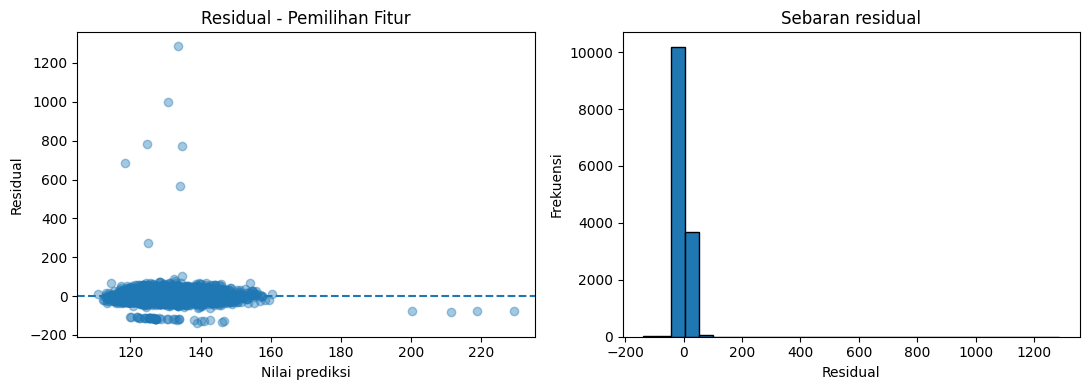

In [27]:
import matplotlib.pyplot as plt

residual = y_uji - duga_uji
fig, (kiri, kanan) = plt.subplots(1, 2, figsize=(11, 4))

kiri.scatter(duga_uji, residual, alpha=0.4)
kiri.axhline(0, linestyle="--")
kiri.set_xlabel("Nilai prediksi"); kiri.set_ylabel("Residual")
kiri.set_title(f"Residual - {nama_varian}")

kanan.hist(residual, bins=30, edgecolor="black")
kanan.set_xlabel("Residual"); kanan.set_ylabel("Frekuensi")
kanan.set_title("Sebaran residual")
plt.tight_layout(); plt.show()

### Penafsiran — ISI SEL INI

- Fitur paling berpengaruh dan besarnya: cholesterol_1, -4,6072.
- Arah hubungannya: cholesterol_1 memiliki koefisien negatif -4,6072, yang mana menunjukkan arah hubungan prediksi yang berlawanan.
- Yang terlihat pada grafik residual kiri: <br>1. Sebagian besar titik terkumpul pada nilai prediksi sekitar 110–160.<br>2. Sebagian besar residual berada di sekitar garis nol.<br>3. Terdapat beberapa residual positif yang sangat ekstrem, bahkan mencapai lebih dari 1.200.<br>4. Terdapat pula residual negatif pada nilai prediksi yang lebih tinggi, sekitar 200–230.
- Yang terlihat pada histogram kanan: Sebagian besar residual terkumpul di sekitar nol dan distribusi residual tidak simetris. Terdapat juga ekor panjang ke arah kanan akibat beberapa residual positif yang sangat besar.
- Konsekuensinya terhadap kesimpulan: Walaupun Varian 3 merupakan varian terbaik dibandingkan Varian 1 dan 2, akan tetapi nilai R² masih rendah. Nilai RMSE juga jauh lebih besar daripada MAE yang menunjukkan adanya beberapa kesalahan prediksi yang ekstrem.

Koefisien menunjukkan **asosiasi**, bukan hubungan sebab-akibat. Kalimat ini
wajib ada di laporan. Asumsi yang dilanggar juga tidak membuat proyek gagal —
yang dinilai adalah Anda menyadarinya, menuliskannya, dan menjelaskan
konsekuensinya.

---
## Langkah G — Menyimpan hasil ke Drive

In [28]:
joblib.dump(model_terpilih, os.path.join(FOLDER, "model_terpilih.joblib"))

metrik = {
    "varian_terpilih": VARIAN_TERPILIH,
    "nama_varian": nama_varian,
    "anggota": hasil[VARIAN_TERPILIH]["anggota"],
    "mae": float(mae_uji),
    "rmse": float(rmse_uji),
    "r2": float(r2_uji),
    "r2_garis_dasar": float(r2_dasar),
    "sidik_jari_uji": sidik_p12,
    "penskalaan_mengubah_prediksi": bool(selisih >= 1e-6),
    "perbandingan_varian": [
        {k: (float(v) if k != "varian" else v) for k, v in b.items()} for b in baris
    ],
    "rincian_varian": {str(n): hasil[n] for n in (1, 2, 3)},
}

with open(os.path.join(FOLDER, "p13_metrik.json"), "w", encoding="utf-8") as f:
    json.dump(metrik, f, indent=2, ensure_ascii=False)

print("Tersimpan: model_terpilih.joblib dan p13_metrik.json")
print("\nIsi folder:", sorted(os.listdir(FOLDER)))

Tersimpan: model_terpilih.joblib dan p13_metrik.json

Isi folder: ['data_mentah.csv', 'model_terpilih.joblib', 'p12_data.joblib', 'p13_metrik.json', 'varian1.joblib', 'varian1_hasil.json', 'varian2.joblib', 'varian2_hasil.json', 'varian3.joblib', 'varian3_hasil.json']


---
## Isi folder Drive setelah Pertemuan 13

```
ProyekML_RegresiLinear/          ← folder Google Drive kelompok
├── data_mentah.csv              · dari bagian bersama
├── p12_data.joblib              · dari bagian bersama, DIBACA HARI INI
├── varian1.joblib               · dari Anggota 1, DIBACA HARI INI
├── varian1_hasil.json           · dari Anggota 1, DIBACA HARI INI
├── varian2.joblib               · dari Anggota 2, DIBACA HARI INI
├── varian2_hasil.json           · dari Anggota 2, DIBACA HARI INI
├── varian3.joblib               · dari Anggota 3, DIBACA HARI INI
├── varian3_hasil.json           · dari Anggota 3, DIBACA HARI INI
├── model_terpilih.joblib        ← DIHASILKAN HARI INI
└── p13_metrik.json              ← DIHASILKAN HARI INI
```

Keenam berkas varian tidak dihapus. Pertemuan 15 memakainya untuk menuliskan
tabel perbandingan ke README repositori.

## Daftar periksa

- [ ] Sel Langkah C mencetak `Lengkap. Ketiga varian sudah dikerjakan.`
- [ ] Sel sidik jari mencetak `Perbandingan sah.`
- [ ] Garis dasar dilaporkan bersama ketiga varian
- [ ] Tabel perbandingan sudah dijalankan dan sel isiannya diisi angka
- [ ] Sel pemeriksaan penskalaan sudah dijalankan dan hasilnya dipahami
- [ ] `VARIAN_TERPILIH` diisi sesuai keputusan kelompok
- [ ] Alasan pemilihan tertulis, menyebut metrik penentu
- [ ] Setiap anggota menulis sendiri alasan variannya menang atau kalah
- [ ] Sel penafsiran terisi dengan apa yang benar-benar terlihat
- [ ] Sel Langkah G mencetak `Tersimpan: model_terpilih.joblib dan p13_metrik.json`